# Using BSpline.jl

Plot a cubic B-spline basis and its first and second derivatives, and check the
derivatives against automatic differentiation.

The first cell sets up a temporary environment with BSpline.jl from this
repository and the plotting and differentiation packages used below.

In [1]:
using Pkg
Pkg.activate(temp=true; io=devnull)
Pkg.develop(path=@__DIR__; io=devnull)   # the BSpline.jl repository
Pkg.add(["Plots", "ForwardDiff"]; io=devnull)
using BSpline, Plots, ForwardDiff
default(fmt=:png)   # embed plots as PNG only

## The basis

Cubic splines (order `M = 4`) with 6 equally spaced knots on $[1, 6]$.
`BSplineT` adds `M - 1 = 3` knots on each side, which gives 8 basis functions
that sum to one on $[1, 6]$ (dashed lines).

In [2]:
M = 4
bs = BSplineT(M, 1.0, 6.0, 6)
nb = num_basis(bs)
@show nb bs.knots;

nb = 8


bs.knots = [-2.0, -1.0, 0.0, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0]


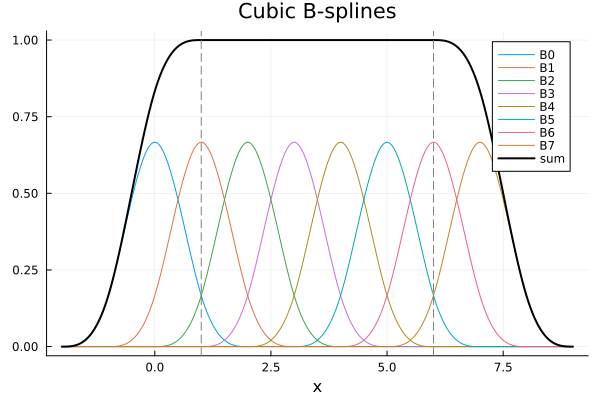

In [3]:
x = -2:0.01:9
labels = permutedims(["B$j" for j in 0:nb-1])

B = bspline_basismatrix(bs, x)
plot(x, B; label=labels, xlabel="x", title="Cubic B-splines")
plot!(x, sum(B; dims=2); color=:black, linewidth=2, label="sum")
vline!([1, 6]; color=:gray, linestyle=:dash, label="")

## Derivatives

The first derivatives are continuous and piecewise quadratic. The second
derivatives are continuous and piecewise linear.

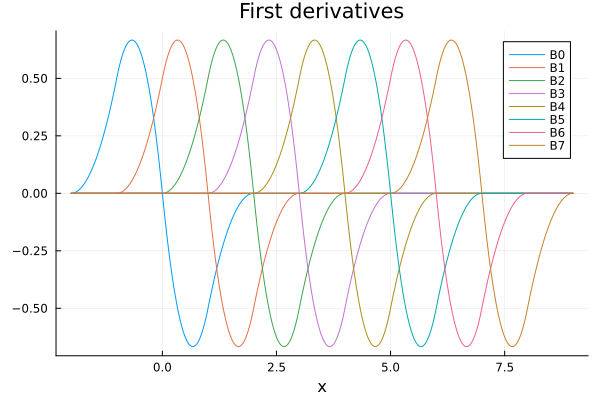

In [4]:
D1 = derivative_bspline_basismatrix(bs, x)
plot(x, D1; label=labels, xlabel="x", title="First derivatives")

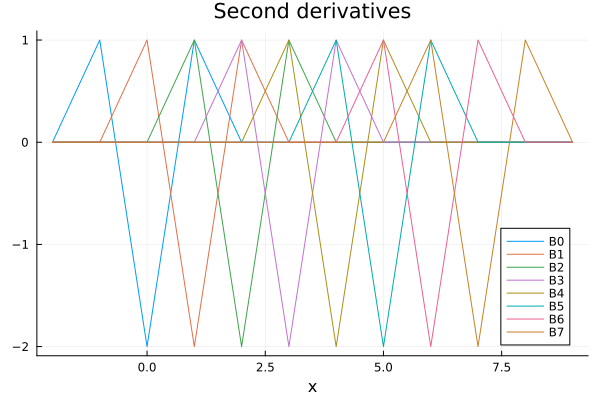

In [5]:
D2 = derivative2_bspline_basismatrix(bs, x)
plot(x, D2; label=labels, xlabel="x", title="Second derivatives")

## Check against automatic differentiation

The scalar functions accept ForwardDiff's dual numbers, so ForwardDiff can
differentiate `bspline_basis` and `derivative_bspline_basis` directly. The
differences from the analytic derivatives are at the level of rounding error.

In [6]:
AD1 = [ForwardDiff.derivative(z -> bspline_basis(j, bs, z), xk) for xk in x, j in 0:nb-1]
AD2 = [ForwardDiff.derivative(z -> derivative_bspline_basis(j, bs, z), xk) for xk in x, j in 0:nb-1]
@show maximum(abs, D1 - AD1) maximum(abs, D2 - AD2);

maximum(abs, D1 - AD1) = 2.7755575615628914e-16


maximum(abs, D2 - AD2) = 4.440892098500626e-16
